### **Импорты и загрузка данных**

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import butter, filtfilt, find_peaks, welch
from scipy.stats import kurtosis, skew
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, silhouette_samples

In [2]:
root = Path.cwd().parent if Path.cwd().name == 'your-sollution' else Path.cwd()
train = np.load(root / 'dataset/task2_2/train.npz')
test = np.load(root / 'dataset/task2_2/test_features.npz')

In [3]:
meta = json.loads(str(train['meta_json']))
fs = meta['sampling_rate_hz']
X = train['X'][:, :, 0].astype(np.float64)
X_test = test['X'][:, :, 0].astype(np.float64)
subjects = train['subject_id']
test_subjects = test['subject_id']
label_names = train['label_names']

print('Частота:', fs, 'Гц, длина окна:', meta['window_seconds'], 'с')
print('train:', X.shape, ' test:', X_test.shape)
print('Испытуемых:', len(np.unique(subjects)))

Частота: 500 Гц, длина окна: 8 с
train: (48, 4000)  test: (24, 4000)
Испытуемых: 8


In [4]:
y = train['prediction']
activity = pd.Categorical(label_names[y], categories=label_names)
pd.crosstab(subjects, activity, rownames=['испытуемый'], colnames=['активность'])

активность,sit,walk,run
испытуемый,,,
1,2,2,2
2,2,2,2
3,2,2,2
4,2,2,2
5,2,2,2
6,2,2,2
7,2,2,2
8,2,2,2


### **Исходные сигналы PPG**

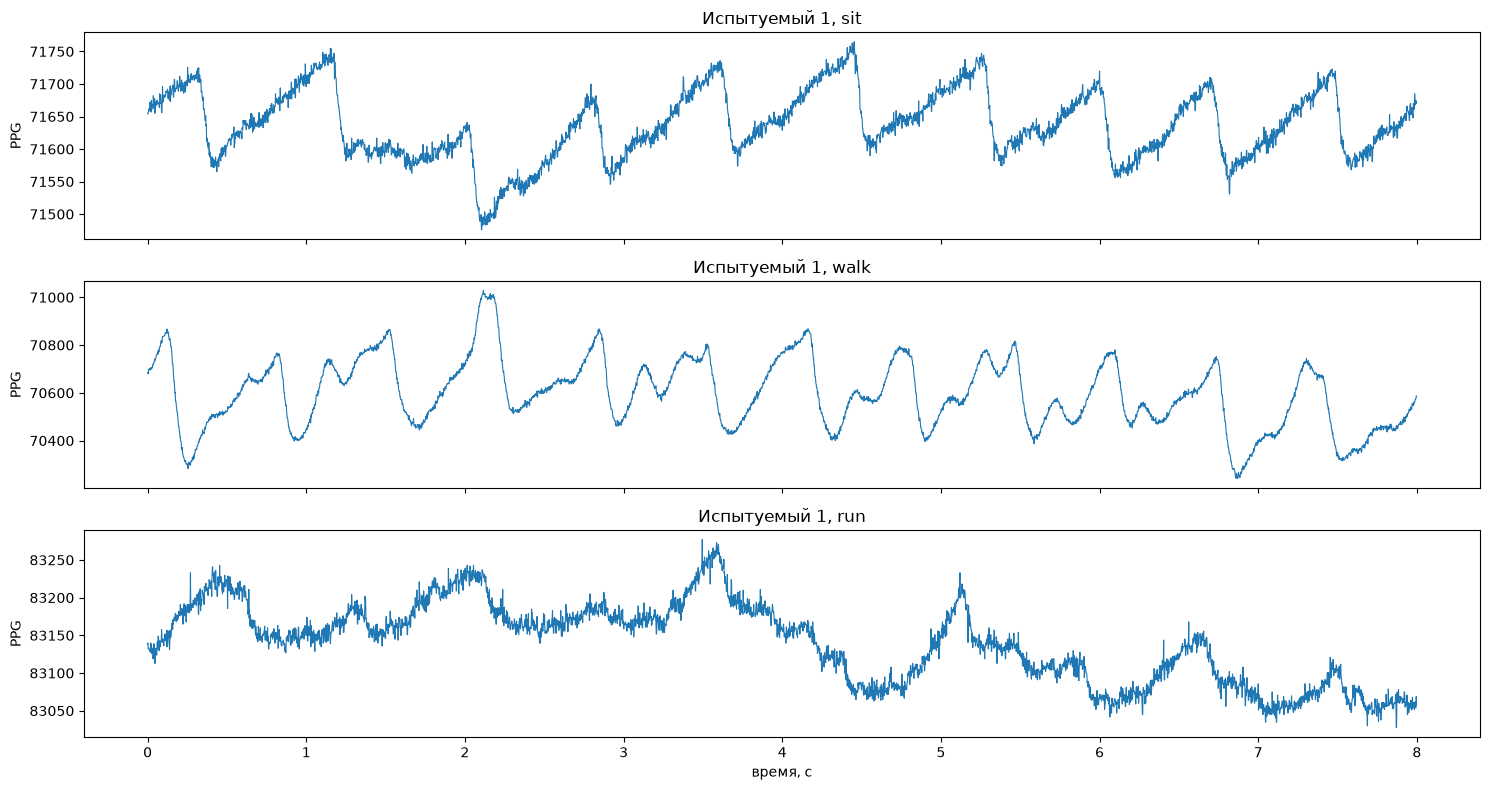

In [5]:
t = np.arange(X.shape[1]) / fs
fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
for ax, name in zip(axes, label_names):
    idx = np.where((subjects == 1) & (activity == name))[0][0]
    ax.plot(t, X[idx], linewidth=0.8)
    ax.set_title(f'Испытуемый 1, {name}')
    ax.set_ylabel('PPG')
axes[-1].set_xlabel('время, с')
plt.tight_layout()
plt.show()

In [6]:
pd.DataFrame({'испытуемый': subjects, 'среднее': X.mean(axis=1), 'std': X.std(axis=1)}).groupby('испытуемый').mean().round(1)

,среднее,std
испытуемый,,
1,75124.0,87.6
2,76495.7,118.6
3,80311.6,194.0
4,81649.4,174.5
5,77128.0,105.8
6,66566.4,85.1
7,64019.7,109.4
8,73504.7,208.1


### **Полосовой фильтр 0.5–8 Гц и спектр**

In [7]:
b, a = butter(4, [0.5, 8], btype='band', fs=fs)

def bandpass(sig):
    return filtfilt(b, a, sig)

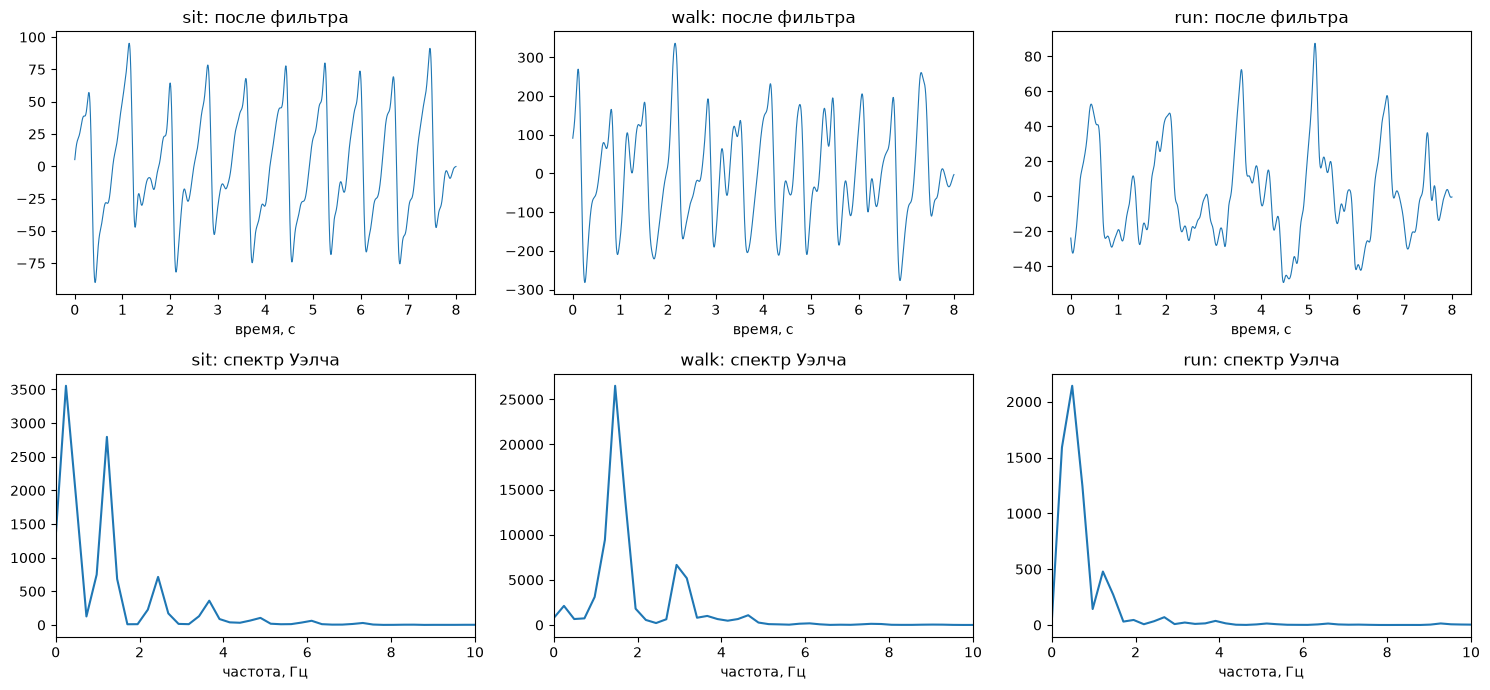

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for col, name in enumerate(label_names):
    idx = np.where((subjects == 1) & (activity == name))[0][0]
    sig = X[idx] - X[idx].mean()
    axes[0, col].plot(t, bandpass(sig), linewidth=0.8)
    axes[0, col].set_title(f'{name}: после фильтра')
    axes[0, col].set_xlabel('время, с')
    freqs, psd = welch(sig, fs=fs, nperseg=2048)
    axes[1, col].plot(freqs, psd)
    axes[1, col].set_xlim(0, 10)
    axes[1, col].set_title(f'{name}: спектр Уэлча')
    axes[1, col].set_xlabel('частота, Гц')
plt.tight_layout()
plt.show()

### **Извлечение признаков**

На каждое окно считаем 15 признаков:
- временные: доля сигнала в полосе 0.5–8 Гц, эксцесс, асимметрия, пик автокорреляции (насколько сигнал периодичен);
- спектральные: ЧСС по пику спектра, доли мощности в полосах 0.1–0.7 / 0.7–3.5 / 3.5–30 Гц, спектральная энтропия;
- пульсовые: ЧСС по числу пиков и разброс интервалов между пиками;
- вейвлетные: доли энергии вейвлета Хаара в полосах ≈ 4–8, 2–4, 1–2 и < 1 Гц.

In [9]:
def haar_energy(sig, levels=8):
    approx = sig[:len(sig) // 2 ** levels * 2 ** levels]
    energy = []
    for _ in range(levels):
        detail = (approx[0::2] - approx[1::2]) / np.sqrt(2)
        approx = (approx[0::2] + approx[1::2]) / np.sqrt(2)
        energy.append(np.sum(detail ** 2))
    energy.append(np.sum(approx ** 2))
    energy = np.array(energy) / np.sum(energy)
    return energy[5:]

In [10]:
def extract_features(sig):
    sig = sig - sig.mean()
    filt = bandpass(sig)

    freqs, psd = welch(sig, fs=fs, nperseg=2048)
    band = (freqs >= 0.1) & (freqs < 30)
    total = psd[band].sum()
    p = psd[band] / total
    cardiac = (freqs >= 0.7) & (freqs < 3.5)

    peaks, _ = find_peaks(filt, distance=int(0.3 * fs), prominence=0.3 * filt.std())
    ibi = np.diff(peaks) / fs

    z = (filt - filt.mean()) / filt.std()
    acf = np.correlate(z, z, 'full')[len(z) - 1:] / len(z)

    wav = haar_energy(sig)
    return {
        'filt_ratio': filt.std() / sig.std(),
        'kurtosis': kurtosis(filt),
        'skewness': skew(filt),
        'acf_peak': acf[int(0.3 * fs):int(1.5 * fs)].max(),
        'hr_spectrum': freqs[cardiac][np.argmax(psd[cardiac])] * 60,
        'p_low': psd[(freqs >= 0.1) & (freqs < 0.7)].sum() / total,
        'p_cardiac': psd[cardiac].sum() / total,
        'p_high': psd[(freqs >= 3.5) & (freqs < 30)].sum() / total,
        'spec_entropy': -np.sum(p * np.log(p + 1e-12)),
        'hr_peaks': len(peaks) / (len(sig) / fs) * 60,
        'ibi_std': ibi.std(),
        'wav_4-8Hz': wav[0],
        'wav_2-4Hz': wav[1],
        'wav_1-2Hz': wav[2],
        'wav_<1Hz': wav[3],
    }

In [11]:
features = pd.DataFrame([extract_features(sig) for sig in X])
features_test = pd.DataFrame([extract_features(sig) for sig in X_test])
print('Пропусков в train:', features.isna().sum().sum())
print('Пропусков в test:', features_test.isna().sum().sum())
features.describe().T.round(3)

Пропусков в train: 0
Пропусков в test: 0


,count,mean,std,min,25%,50%,75%,max
filt_ratio,48.0,0.731,0.240,0.088,0.647,0.810,0.893,1.009
kurtosis,48.0,-0.508,0.871,-1.276,-0.938,-0.672,-0.349,4.333
skewness,48.0,0.016,0.328,-0.543,-0.193,0.057,0.166,0.670
acf_peak,48.0,0.684,0.167,0.169,0.610,0.724,0.811,0.893
hr_spectrum,48.0,83.923,26.298,43.945,73.242,73.242,87.891,190.430
p_low,48.0,0.228,0.251,0.014,0.054,0.139,0.275,0.903
p_cardiac,48.0,0.690,0.230,0.075,0.598,0.765,0.863,0.942
p_high,48.0,0.082,0.073,0.006,0.041,0.069,0.085,0.345
spec_entropy,48.0,1.993,0.390,0.771,1.788,2.059,2.252,2.659
hr_peaks,48.0,93.750,18.694,60.000,82.500,90.000,112.500,142.500


### **Влияние испытуемого на признаки**

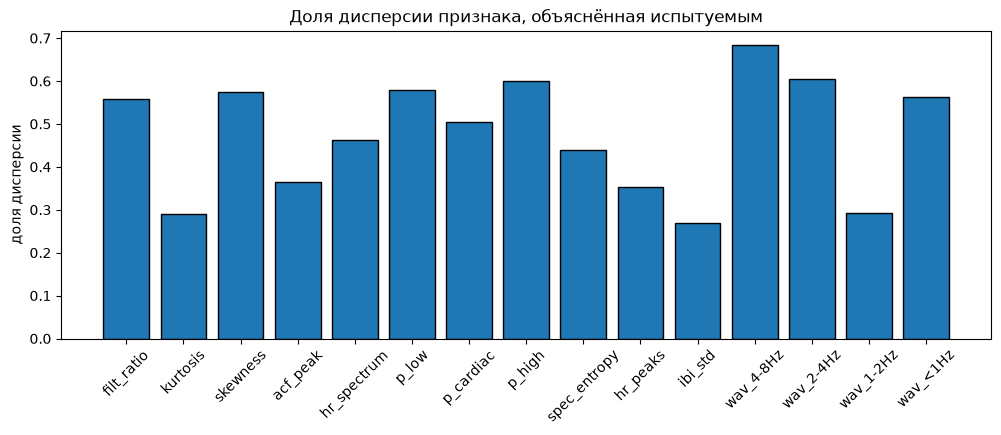

В среднем: 0.476


In [12]:
subject_share = features.groupby(subjects).transform('mean').var() / features.var()

plt.figure(figsize=(12, 4))
plt.bar(subject_share.index, subject_share.values, edgecolor='black')
plt.xticks(rotation=45)
plt.ylabel('доля дисперсии')
plt.title('Доля дисперсии признака, объяснённая испытуемым')
plt.show()

print('В среднем:', round(subject_share.mean(), 3))

### **Нормализация: глобальная и внутри испытуемого**

In [13]:
Z_global = StandardScaler().fit_transform(features)

subject_scalers = {s: StandardScaler().fit(features[subjects == s]) for s in np.unique(subjects)}

def subject_normalize(feats, subj):
    Z = np.zeros(feats.shape)
    for s in np.unique(subj):
        Z[subj == s] = subject_scalers[s].transform(feats[subj == s])
    return Z

Z_subject = subject_normalize(features, subjects)

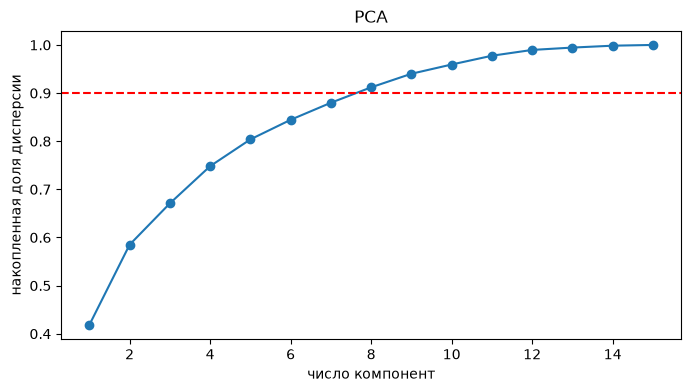

Компонент для 90% дисперсии: 8


In [14]:
cumvar = np.cumsum(PCA().fit(Z_subject).explained_variance_ratio_)
n_comp = np.argmax(cumvar >= 0.9) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumvar) + 1), cumvar, marker='o')
plt.axhline(0.9, color='red', linestyle='--')
plt.xlabel('число компонент')
plt.ylabel('накопленная доля дисперсии')
plt.title('PCA')
plt.show()

print('Компонент для 90% дисперсии:', n_comp)

In [15]:
pca_global = PCA(n_components=n_comp, random_state=42)
E_global = pca_global.fit_transform(Z_global)

pca = PCA(n_components=n_comp, random_state=42)
E = pca.fit_transform(Z_subject)

### **Сравнение нормализаций на KMeans**

In [16]:
km_global = KMeans(n_clusters=3, n_init=20, random_state=42).fit_predict(E_global)
km_subject = KMeans(n_clusters=3, n_init=20, random_state=42).fit_predict(E)

pd.DataFrame({
    'ARI с испытуемым': [adjusted_rand_score(subjects, km_global), adjusted_rand_score(subjects, km_subject)],
    'ARI с активностью': [adjusted_rand_score(y, km_global), adjusted_rand_score(y, km_subject)],
}, index=['глобальная', 'внутри испытуемого']).round(3)

,ARI с испытуемым,ARI с активностью
глобальная,0.105,0.002
внутри испытуемого,-0.037,0.260


In [17]:
def plot_crosstab(ct, ax, title):
    ax.imshow(ct.values, cmap='Blues', aspect='auto')
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            color = 'white' if ct.values[i, j] > ct.values.max() / 2 else 'black'
            ax.text(j, i, ct.values[i, j], ha='center', va='center', color=color)
    ax.set_xticks(range(ct.shape[1]), ct.columns)
    ax.set_yticks(range(ct.shape[0]), ct.index)
    ax.set_xlabel(ct.columns.name)
    ax.set_ylabel(ct.index.name)
    ax.set_title(title)

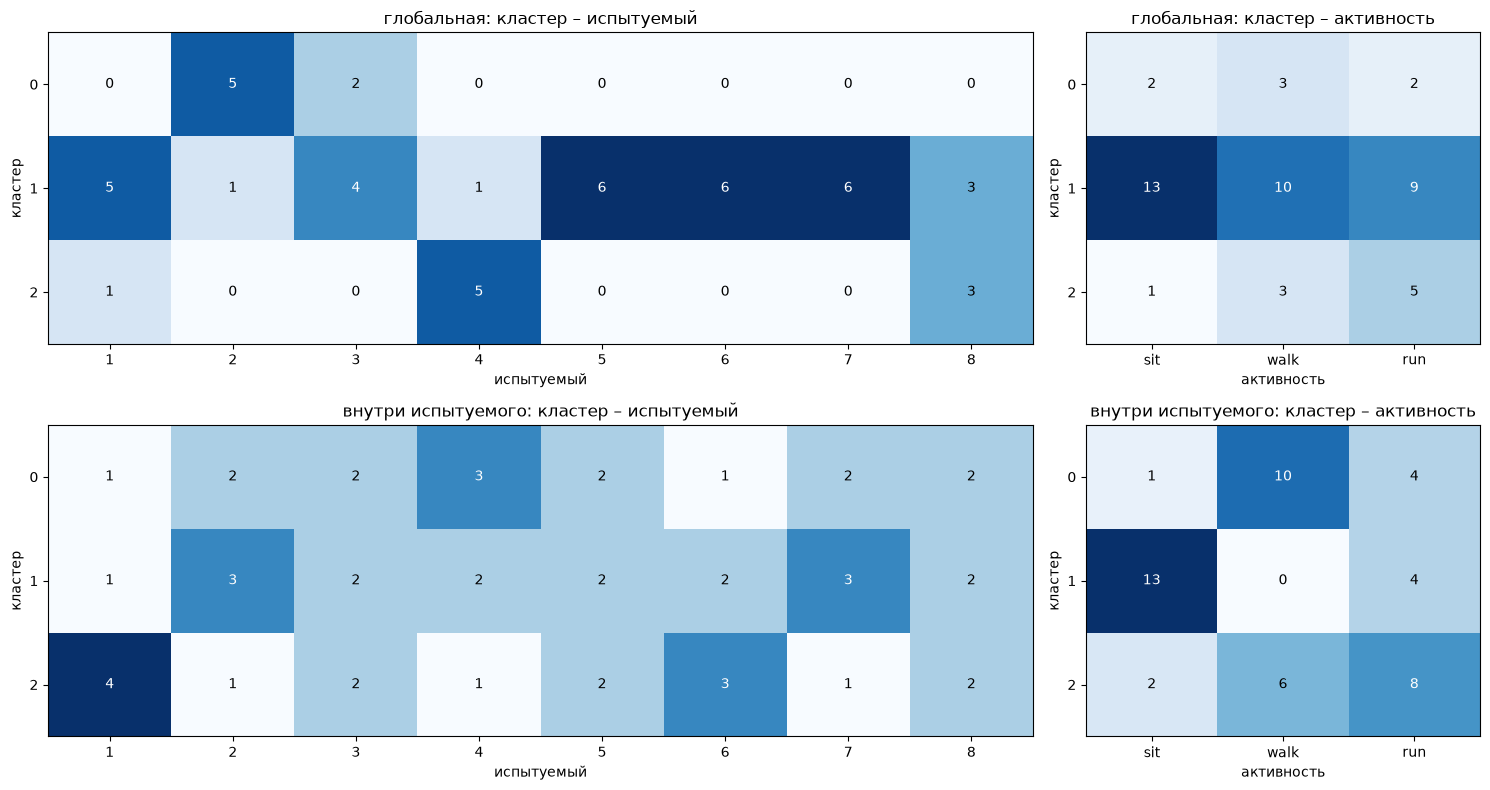

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [2.5, 1]})
for row, (labels, name) in enumerate([(km_global, 'глобальная'), (km_subject, 'внутри испытуемого')]):
    plot_crosstab(pd.crosstab(pd.Series(labels, name='кластер'), pd.Series(subjects, name='испытуемый')),
                  axes[row, 0], f'{name}: кластер – испытуемый')
    plot_crosstab(pd.crosstab(pd.Series(labels, name='кластер'), pd.Series(activity, name='активность')),
                  axes[row, 1], f'{name}: кластер – активность')
plt.tight_layout()
plt.show()

Дальше работаем с нормализацией внутри испытуемого. Решение принимаем без меток активности: при глобальной нормализации кластеры собирают окна отдельных испытуемых (ARI с `subject_id` выше), а нормализация внутри испытуемого эту зависимость убирает.

### **Выбор числа кластеров**

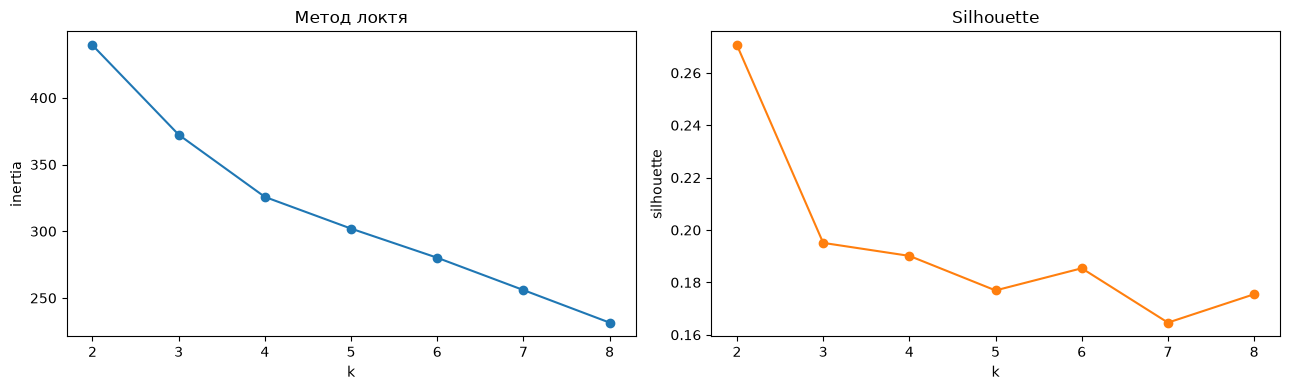

Лучшее k по silhouette: 2


In [19]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(E)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(E, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertia, marker='o')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('k')
axes[0].set_ylabel('inertia')
axes[1].plot(ks, sil, marker='o', color='C1')
axes[1].set_title('Silhouette')
axes[1].set_xlabel('k')
axes[1].set_ylabel('silhouette')
plt.tight_layout()
plt.show()

print('Лучшее k по silhouette:', ks[int(np.argmax(sil))])

Берём k = 3: в протоколе записи три вида активности (сидя, ходьба, бег), это известно из постановки, а не из меток.

### **Сравнение алгоритмов кластеризации**

In [20]:
models = {
    'KMeans': KMeans(n_clusters=3, n_init=20, random_state=42),
    'Agglomerative': AgglomerativeClustering(n_clusters=3, linkage='ward'),
    'Spectral': SpectralClustering(n_clusters=3, affinity='nearest_neighbors', n_neighbors=7, random_state=42),
}

results, cluster_labels = [], {}
for name, model in models.items():
    labels = model.fit_predict(E)
    cluster_labels[name] = labels
    results.append({
        'метод': name,
        'silhouette': silhouette_score(E, labels),
        'ARI': adjusted_rand_score(y, labels),
        'NMI': normalized_mutual_info_score(y, labels),
    })
results = pd.DataFrame(results).set_index('метод').round(3)
results

,silhouette,ARI,NMI
метод,,,
KMeans,0.195,0.260,0.300
Agglomerative,0.184,0.280,0.317
Spectral,0.183,0.275,0.364


In [21]:
best = results['silhouette'].idxmax()
clusters = cluster_labels[best]
print('Выбран метод:', best)

cluster_colors = ['tab:blue', 'tab:purple', 'tab:olive']
activity_colors = {'sit': 'tab:green', 'walk': 'tab:orange', 'run': 'tab:red'}

Выбран метод: KMeans


### **Проекции PCA и t-SNE**

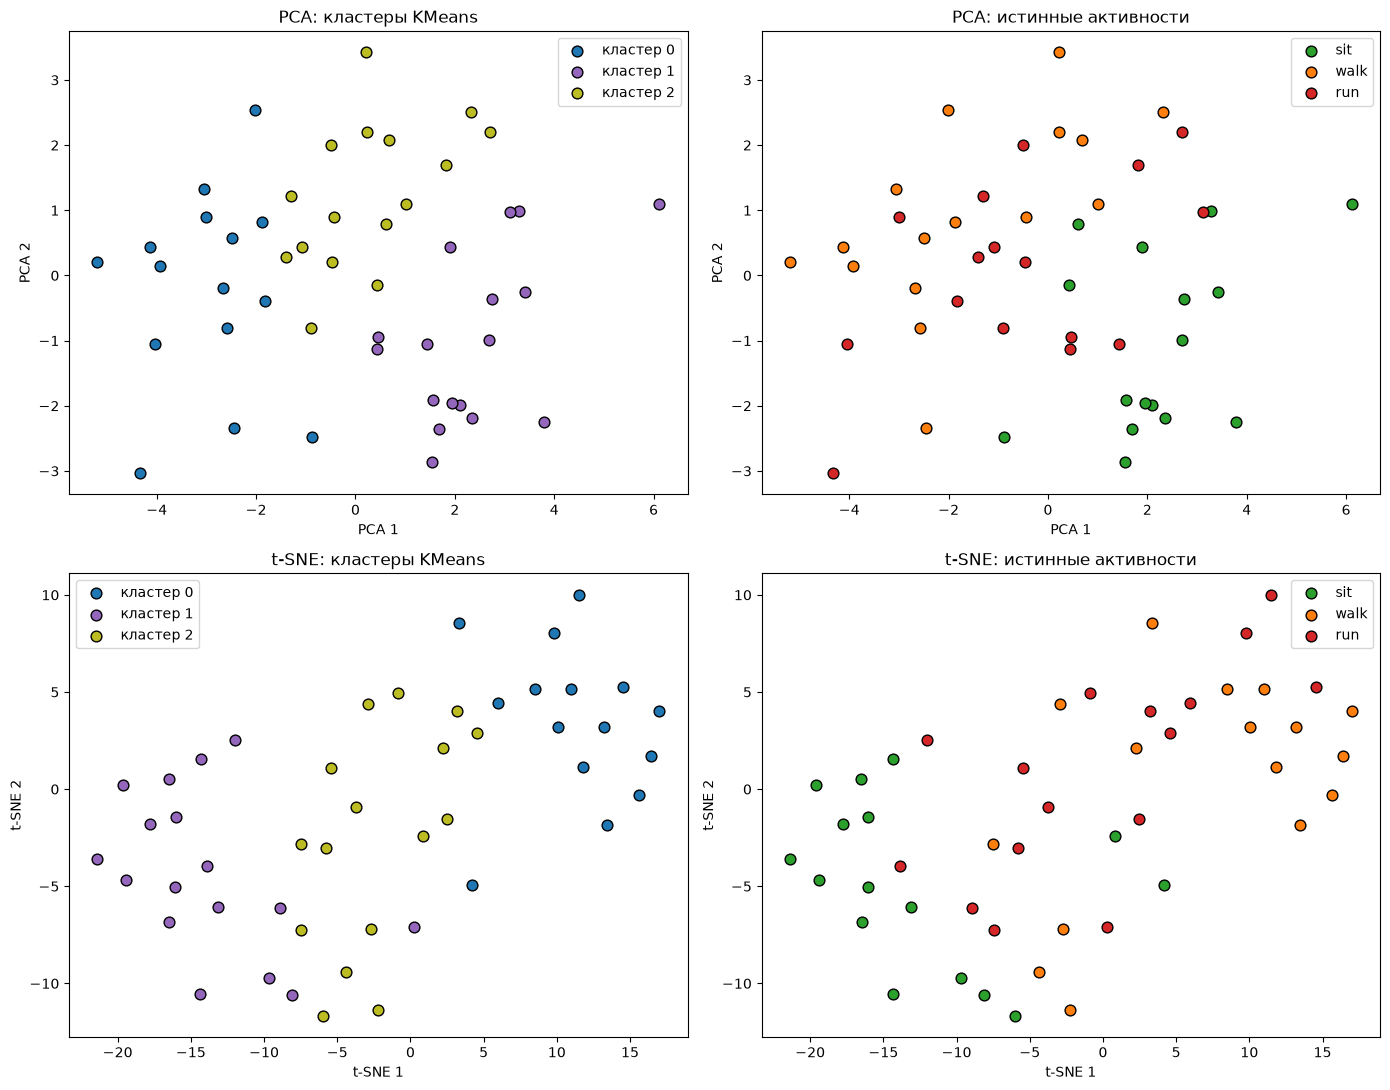

In [22]:
pts_pca = E[:, :2]
pts_tsne = TSNE(n_components=2, perplexity=10, init='pca', random_state=42).fit_transform(Z_subject)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for row, (pts, proj) in enumerate([(pts_pca, 'PCA'), (pts_tsne, 't-SNE')]):
    for k in np.unique(clusters):
        axes[row, 0].scatter(*pts[clusters == k].T, s=60, c=cluster_colors[k], edgecolor='black', label=f'кластер {k}')
    for name in label_names:
        axes[row, 1].scatter(*pts[activity == name].T, s=60, c=activity_colors[name], edgecolor='black', label=name)
    axes[row, 0].set_title(f'{proj}: кластеры {best}')
    axes[row, 1].set_title(f'{proj}: истинные активности')
    for ax in axes[row]:
        ax.set_xlabel(f'{proj} 1')
        ax.set_ylabel(f'{proj} 2')
        ax.legend()
plt.tight_layout()
plt.show()

### **Таблица «кластер–активность»**

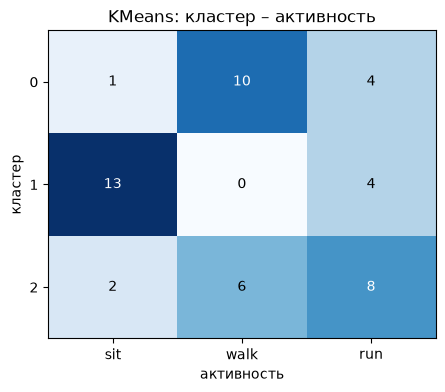

In [23]:
ct = pd.crosstab(pd.Series(clusters, name='кластер'), pd.Series(activity, name='активность'))
fig, ax = plt.subplots(figsize=(5, 4))
plot_crosstab(ct, ax, f'{best}: кластер – активность')
plt.show()

In [24]:
pd.DataFrame(Z_subject, columns=features.columns).groupby(clusters).mean().T.round(2)

,0,1,2
filt_ratio,-1.05,0.76,0.18
kurtosis,0.63,-1.04,0.52
skewness,-0.19,0.24,-0.08
acf_peak,-0.95,0.82,0.03
hr_spectrum,-0.17,-0.44,0.63
p_low,1.09,-0.85,-0.12
p_cardiac,-0.93,0.76,0.06
p_high,-0.46,-0.03,0.47
spec_entropy,0.18,-0.62,0.49
hr_peaks,0.53,-0.87,0.43


### **Анализ силуэтов**

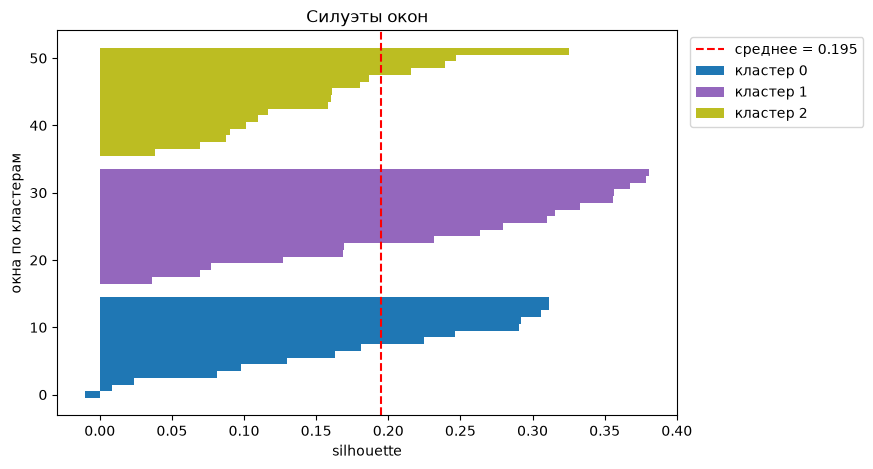

In [25]:
sil_values = silhouette_samples(E, clusters)

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 0
for k in np.unique(clusters):
    vals = np.sort(sil_values[clusters == k])
    ax.barh(range(y_lower, y_lower + len(vals)), vals, height=1, color=cluster_colors[k], label=f'кластер {k}')
    y_lower += len(vals) + 2
ax.axvline(sil_values.mean(), color='red', linestyle='--', label=f'среднее = {sil_values.mean():.3f}')
ax.set_xlabel('silhouette')
ax.set_ylabel('окна по кластерам')
ax.set_title('Силуэты окон')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.show()

In [26]:
pd.Series(sil_values).groupby(activity).mean().round(3)

sit     0.249
walk    0.195
run     0.142
dtype: float64

### **Дендрограмма**

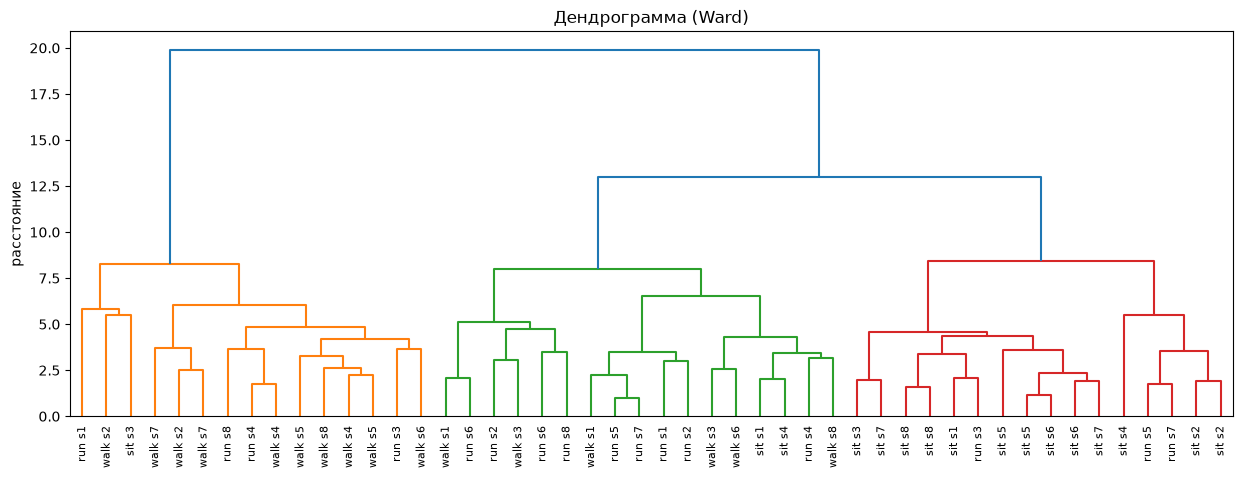

In [27]:
Z_link = linkage(E, method='ward')
leaf_labels = [f'{a} s{s}' for a, s in zip(activity, subjects)]

plt.figure(figsize=(15, 5))
dendrogram(Z_link, labels=leaf_labels, leaf_rotation=90, color_threshold=Z_link[-2, 2])
plt.ylabel('расстояние')
plt.title('Дендрограмма (Ward)')
plt.show()

### **Типичные окна кластеров**

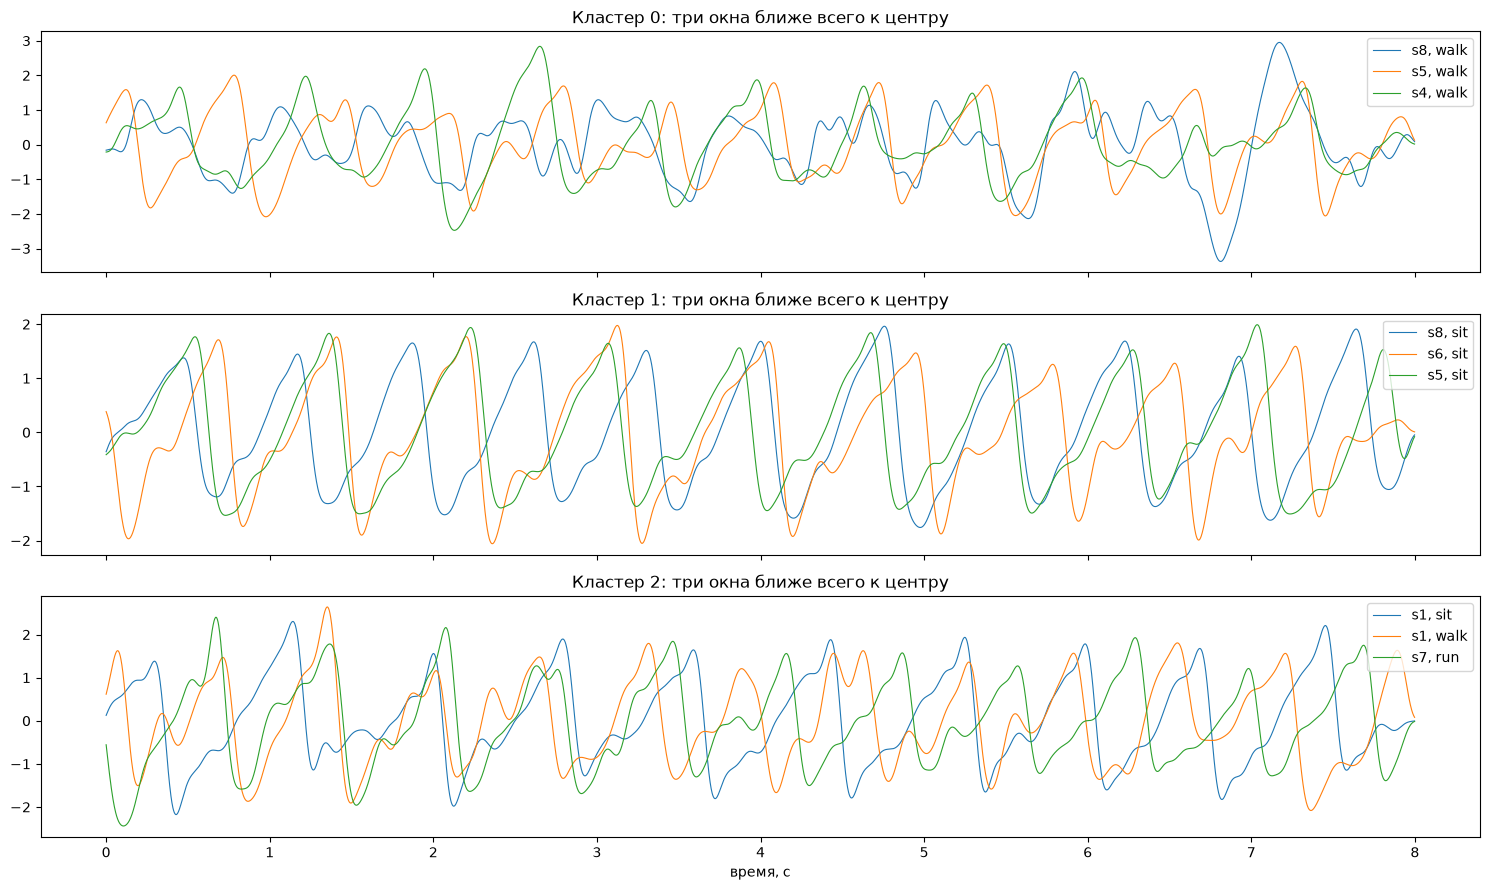

In [28]:
centroids = np.array([E[clusters == k].mean(axis=0) for k in np.unique(clusters)])

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, k in zip(axes, np.unique(clusters)):
    dist = np.linalg.norm(E - centroids[k], axis=1)
    dist[clusters != k] = np.inf
    for idx in np.argsort(dist)[:3]:
        filt = bandpass(X[idx] - X[idx].mean())
        ax.plot(t, filt / filt.std(), linewidth=0.8, label=f's{subjects[idx]}, {activity[idx]}')
    ax.set_title(f'Кластер {k}: три окна ближе всего к центру')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('время, с')
plt.tight_layout()
plt.show()

### **Кластеры для test_features.npz**

In [29]:
print('Все испытуемые test есть в train:', set(test_subjects) <= set(subjects))

E_test = pca.transform(subject_normalize(features_test, test_subjects))

test_clusters = NearestCentroid().fit(E, clusters).predict(E_test)

Все испытуемые test есть в train: True


In [30]:
submission = pd.DataFrame({
    'window_id': test['window_id'],
    'prediction': test_clusters,
})
submission.head()

,window_id,prediction
0,3,0
1,6,1
2,7,2
3,12,2
4,13,1


In [31]:
submission['prediction'].value_counts()

prediction
2    11
1     7
0     6
Name: count, dtype: int64

### **Сохранение в outputs/task2_2_predictions.csv**

In [32]:
submission.to_csv(root / 'outputs/task2_2_predictions.csv', index=False)

In [33]:
saved = pd.read_csv(root / 'outputs/task2_2_predictions.csv')
print('Файл сохранён:', saved.shape)
print('Пропусков:', saved.isna().sum().sum())
print('window_id совпадают:', (saved['window_id'].values == test['window_id']).all())

Файл сохранён: (24, 2)
Пропусков: 0
window_id совпадают: True


### **Отчёт**

1. **Сигнал.** Из окна убираем среднее и фильтруем 0.5–8 Гц. Признаки: временные (доля сигнала в полосе, эксцесс, асимметрия, автокорреляция), спектральные (ЧСС по пику спектра, доли мощности 0.1–0.7 / 0.7–3.5 / 3.5–30 Гц, энтропия), пульсовые (ЧСС по пикам, разброс интервалов) и энергии вейвлета Хаара по полосам.
2. **Нормализация.** Испытуемый объясняет в среднем 48% дисперсии признаков (случайно было бы ≈ 15%). При глобальной нормализации KMeans группирует окна по людям: ARI с испытуемым 0.105, с активностью 0.002. После z-нормализации внутри испытуемого: −0.04 и 0.26. Для test берутся scaler'ы испытуемых из train.
3. **Метод.** PCA до 90% дисперсии (8 компонент), k = 3 по протоколу записи. Silhouette максимален при k = 2 — данные делятся на «покой» и «движение». Из KMeans, Ward и спектральной кластеризации по silhouette выбран KMeans (0.195 против 0.184 и 0.183), метки в выборе не участвуют.
4. **Метрики на train.** ARI = 0.26, NMI = 0.30, silhouette = 0.195; при других `random_state` ARI 0.25–0.28. В кластере 1 — 13 из 16 сидячих окон, в кластере 0 — 10 окон ходьбы, кластер 2 смешанный (8 бег, 6 ходьба). Средний силуэт: sit 0.25, walk 0.20, run 0.14.
5. **Почему сидя отделяется лучше.** В покое PPG — чистая периодическая пульсовая волна: высокая доля мощности в полосе пульса и автокорреляция, ровные интервалы между пиками. При ходьбе и беге появляются артефакты движения и дрейф базовой линии, а частота шагов и движений руки (≈ 1–3 Гц) совпадает с диапазоном пульса, поэтому оба вида активности искажают волну похоже. ЧСС у них тоже близка (≈ 103 и 98 уд/мин по пикам против 81 сидя), а интенсивность движения одноканальный PPG передаёт лишь косвенно — без акселерометра ходьбу и бег различить трудно.
6. **Ограничения.** Всего 48 окон от 8 испытуемых, поэтому оценки метрик грубые.